In [1]:
import os, sys
import warnings
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
warnings.simplefilter('ignore', FutureWarning)

In [2]:
# import KM survival analysis wrapper
pth0, _ = os.path.split(os.getcwd())
sys.path.append(pth0)
from scripts.survival import fit_survival

In [3]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'TCGA')
pth_out = os.path.join(pth, 'figures', 'emtarget', 'biomarkers')

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'PANCAN.h5ad'))
adata

AnnData object with n_obs × n_vars = 10535 × 238
    obs: '_PATIENT', 'cancer type abbreviation', 'age_at_initial_pathologic_diagnosis', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'clinical_stage', 'histological_type', 'histological_grade', 'initial_pathologic_dx_year', 'menopause_status', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'cause_of_death', 'new_tumor_event_type', 'new_tumor_event_site', 'new_tumor_event_site_other', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'margin_status', 'residual_tumor', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Redaction'
    uns: 'log1p'

In [5]:
# select primary/main tumors (only)
code = adata.obs_names.str[13:15]
is_skcm = (adata.obs['cancer type abbreviation'] == 'SKCM')
keep = code.isin(['01', '03']) | (is_skcm & (code == '06'))
adata = adata[keep].copy(); adata

AnnData object with n_obs × n_vars = 9725 × 238
    obs: '_PATIENT', 'cancer type abbreviation', 'age_at_initial_pathologic_diagnosis', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'clinical_stage', 'histological_type', 'histological_grade', 'initial_pathologic_dx_year', 'menopause_status', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'cause_of_death', 'new_tumor_event_type', 'new_tumor_event_site', 'new_tumor_event_site_other', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'margin_status', 'residual_tumor', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Redaction'
    uns: 'log1p'

In [6]:
# mean vx panel expression -> biomarker
bm = 'Vx Panel'
g_vx = ['ANXA5', 'ARL6IP1', 'LAPTM4A',
        'PPIB', 'SPINT2', 'SPINT1']
X_vx = adata[:, g_vx].X.mean(axis = 1)
X = adata.X.mean(axis = 1)
adata.obs[bm] = np.asarray(X_vx - X)

In [7]:
cancer_types_dict = {
    'ACC'  : 'Adrenocortical Cancer',
    'BLCA' : 'Bladder Cancer',
    'BRCA' : 'Breast Cancer',
    'CESC' : 'Cervical Cancer',
    'CHOL' : 'Bile Duct Cancer',
    'COAD' : 'Colon Cancer',
    'DLBC' : 'Large B-cell Lymphoma',
    'ESCA' : 'Esophageal Cancer',
    'GBM'  : 'Glioblastoma',
    'HNSC' : 'Head and Neck Cancer',
    'KICH' : 'Kidney Chromophobe',
    'KIRC' : 'Kidney Clear Cell Carcinoma',
    'KIRP' : 'Kidney Papillary Cell Carcinoma',
    'LAML' : 'Acute Myeloid Leukemia',
    'LGG'  : 'Lower Grade Glioma',
    'LIHC' : 'Liver Cancer',
    'LUAD' : 'Lung Adenocarcinoma',
    'LUSC' : 'Lung Squamous Cell Carcinoma',
    'MESO' : 'Mesothelioma',
    'OV'   : 'Ovarian Cancer',
    'PAAD' : 'Pancreatic Cancer',
    'PCPG' : 'Pheochromocytoma & Paraganglioma',
    'PRAD' : 'Prostate Cancer',
    'READ' : 'Rectal Cancer',
    'SARC' : 'Sarcoma',
    'SKCM' : 'Melanoma',
    'STAD' : 'Stomach Cancer',
    'TGCT' : 'Testicular Cancer',
    'THCA' : 'Thyroid Cancer',
    'THYM' : 'Thymoma',
    'UCEC' : 'Endometrioid Cancer',
    'UCS'  : 'Uterine Carcinosarcoma',
    'UVM'  : 'Ocular Melanomas'}

survival_types_dict = {
    'OS'  : 'Overall Survival',
    'DSS' : 'Disease-Specific Survival',
    'DFI' : 'Disease-Free Interval',
    'PFI' : 'Progresssion-Free Interval'}

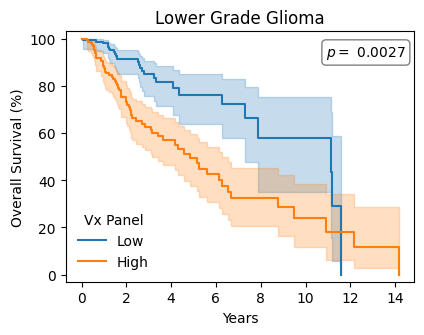

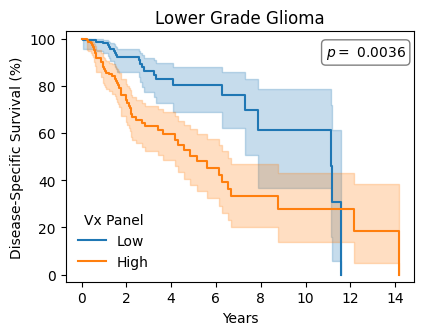

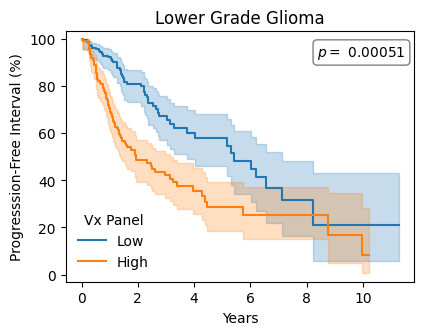

In [8]:
# plot survival -> save significant biomarkers
n_tests = len(cancer_types_dict) * len(survival_types_dict)
for cancer_type, cancer_name in cancer_types_dict.items():
    for survival_type, survival_name in survival_types_dict.items():
        out = fit_survival(adata, bm,
                           cancer_type,
                           survival_type,
                           n_tests = n_tests,
                           title = cancer_name,
                           ylabel = survival_name,
                           figsize = (4.5, 3.25))
        if out and out[1] < .05:
            fn = f'{cancer_type}_{survival_type}.pdf'
            plt.savefig(os.path.join(pth_out, fn), bbox_inches = 'tight')
        elif out: plt.close()